# Diabetes readmission: preprocessing and model comparison

NOVA IMS Enterprise Data Science Bootcamp, 2026-27. Luis Alcaide.

In this notebook I go from the raw `diabetic_data.csv` to a chosen model, step by
step, following the structure of the Classes 6 and 7 classification notebook: three
sets, one preprocessing learned on the training rows only, many models compared in
one table, a winner chosen on validation, and the test set opened only once, at the
very end.

The question, from the project brief: **at the moment of discharge, how likely is a
diabetic patient to be readmitted in less than 30 days** (`readmitted == "<30"`), so
that the hospital can prioritise its limited follow-up resources? The Summary at the
end lists, point by point, how the notebook follows the brief.

What changes compared to the class notebook, and why:

- **The split is by patient, not by date.** The same patient can have several
  encounters. If one of them is in training and another one in validation or test,
  the model can recognise the patient instead of learning the risk, and every score
  looks better than it really is. So every split in this notebook is grouped on
  `patient_nbr`.
- **The preprocessing is adapted to each family of models.** Linear models and neural
  networks need scaled numbers and one-hot categories; decision trees and random
  forests do not care about scale; gradient boosting can read categories directly.
  I write one preprocessing function with three variants, all learned on the
  training rows only.
- **The classes are imbalanced** (about 11% positives), so I weight the classes and
  I choose the winner on PR-AUC, not on accuracy.

Functions defined here:

- `clean`: deterministic, row-by-row cleaning that learns nothing from the data.
- `fit_preprocessor` / `transform`: learn the preprocessing on the training rows and
  apply it to any set, in three variants (`linear_nn`, `tree`, `boosting`).
- `scores`: every metric for one set of predictions.
- `run`: fit one model, score it on train and validation, add it to the results matrix.

----------------------------------------------------------------------
# STAGE 0. GET READY
----------------------------------------------------------------------

**0.1** I find the project folder (the first folder above this notebook that has
`src/data_prep.py`), so that the notebook runs wherever it is opened from, and I make
`src/` importable. The project rules say the data must always be loaded through
`src/data_prep.py`, never with a bare `pd.read_csv()`, because the default missing-value
handling of pandas is wrong for this dataset (`"?"` is the real missing marker and
`"None"` means "test not performed"). I also check that the kernel is the `.venv` with
Python 3.13.

In [5]:
import sys
from datetime import date
from pathlib import Path

PROJECT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src" / "data_prep.py").exists()
)
sys.path.insert(0, str(PROJECT / "src"))

print("Project folder :", PROJECT)
print("Python 3.13    :", sys.version_info[:2] == (3, 13))
print("Running .venv  :", ".venv" in sys.executable)
print("Data in place  :", (PROJECT / "data" / "diabetic_data.csv").exists())

Project folder : /Users/catotix/Documents/Programações/Diabetes-Hospital-Readmission-Data-Science-Project
Python 3.13    : True
Running .venv  : True
Data in place  : True


**0.2** All the imports in one place. I only use scikit-learn for the models (it is
what the course uses and it is already in `requirements.txt`): the neural network is
scikit-learn's `MLPClassifier`, a multi-layer perceptron.

In [6]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import metrics
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight

from data_prep import add_mapping_descriptions, load_mappings, load_raw

SEED = 42
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

----------------------------------------------------------------------
# STAGE 1. LOAD AND CLEAN
----------------------------------------------------------------------
Everything in this stage is a fixed rule applied row by row: it does not compute any
mean, frequency or threshold from the data. That is why it can safely run on the whole
dataset **before** the split. Anything that learns from the data (which categories are
frequent, where to clip, how to scale) waits until Stage 3 and is learned on the
training rows only.

**1.1** I load the data with `load_raw()`, parse `IDS_mapping.csv` with
`load_mappings()` (the file is three lookup tables stacked on top of each other, not
one table) and add the readable `*_desc` columns next to the original IDs.
101,766 encounters of 71,518 patients.

In [7]:
mappings = load_mappings()
raw = add_mapping_descriptions(load_raw(), mappings)
print(f"{len(raw):,} encounters, {raw['patient_nbr'].nunique():,} patients")
print(f"<30 rate: {(raw['readmitted'] == '<30').mean():.2%}")
raw.head(3)

101,766 encounters, 71,518 patients
<30 rate: 11.16%


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,...,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,admission_type_desc,discharge_disposition_desc,admission_source_desc
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,...,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO,Unknown,Unknown,Physician Referral
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,...,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30,Emergency,Discharged to home,Emergency Room
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,...,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO,Emergency,Discharged to home,Emergency Room


**1.2 How I include the three ID columns.** `admission_type_id`,
`discharge_disposition_id` and `admission_source_id` are codes. The project brief
asks to decode them with the lookup table before interpreting or filtering them. The
table below does that for each ID column: every code that occurs in the data, its
description, how many encounters have it and their `<30` rate. Three things follow
from it:

- **They are never used as numbers.** Code 22 (rehab, 28% readmitted) is not "twice"
  code 11 (expired, 0%): the order and distance between codes mean nothing. So they
  enter the models as **categories** (one-hot for linear models, neural networks and
  single trees, native categories for gradient boosting).
- **I use the decoded `*_desc` columns as the features, not the raw codes.** They
  carry the same information, with one improvement: several codes all mean "no
  information" (`NULL`, `Not Mapped`, `Not Available`, `Unknown/Invalid`, for
  example discharge codes 18 and 25), and `add_mapping_descriptions()` merges them into
  one `Unknown` level instead of splitting that missing information across 3 or 4
  columns. (D-003) The descriptions also make the results readable.
- **I keep the raw `*_id` columns in the clean data, but not as features.** Filters use
  the IDs (as the decision log says, IDs are the reproducible key), and keeping them
  lets me trace any row back to the source. Step 1.3 uses them to filter.

Many codes have only a handful of encounters (code 12: 3 encounters). Those are grouped
in Stage 3, with a rule learned on the training rows only.

In [8]:
id_tables = []
for col in mappings:
    by_code = raw.groupby([col, col.replace("_id", "_desc")], observed=True)
    table = by_code["readmitted"].agg(
        encounters="size", readmitted_30_rate=lambda s: (s == "<30").mean()
    )
    table = table.rename_axis(["code", "description"]).reset_index()
    id_tables.append(table.assign(id_column=col))
pd.concat(id_tables).set_index(["id_column", "code"]).round(3)

description  encounters  readmitted_30_rate
id_column                code                                                                                   
admission_type_id        1                                             Emergency       53990               0.115
                         2                                                Urgent       18480               0.112
                         3                                              Elective       18869               0.104
                         4                                               Newborn          10               0.100
                         5                                               Unknown        4785               0.103
                         6                                               Unknown        5291               0.111
                         7                                         Trauma Center          21               0.000
                         8                                               Unknown         320               0.084
discharge_disposition_id 1                                    Discharged to home       60234               0.093
                         2     Discharged/transferred to another short term h...        2128               0.161
                         3                         Discharged/transferred to SNF       13954               0.147
                         4                         Discharged/transferred to ICF         815               0.128
                         5     Discharged/transferred to another type of inpa...        1184               0.209
                         6     Discharged/transferred to home with home healt...       12902               0.127
                         7                                              Left AMA         623               0.144
                         8     Discharged/transferred to home under care of H...         108               0.139
                         9             Admitted as an inpatient to this hospital          21               0.429
                         10    Neonate discharged to another hospital for neo...           6               0.000
                         11                                              Expired        1642               0.000
                         12    Still patient or expected to return for outpat...           3               0.667
                         13                                       Hospice / home         399               0.048
                         14                           Hospice / medical facility         372               0.065
                         15    Discharged/transferred within this institution...          63               0.444
                         16    Discharged/transferred/referred another instit...          11               0.000
                         17    Discharged/transferred/referred to this instit...          14               0.000
                         18                                              Unknown        3691               0.124
                         19             Expired at home. Medicaid only, hospice.           8               0.000
                         20    Expired in a medical facility. Medicaid only, ...           2               0.000
                         22    Discharged/transferred to another rehab fac in...        1993               0.277
                         23    Discharged/transferred to a long term care hos...         412               0.073
                         24    Discharged/transferred to a nursing facility c...          48               0.146
                         25                                              Unknown         989               0.093
                         27    Discharged/transferred to a federal health car...           5               0.000
                         28    Discharged/transferred/referred to a psychiatr...         139               0.367
a

**1.3 Death and hospice, found through the lookup table.** A patient who died cannot be
readmitted, so these encounters are labelled "not readmitted" by construction. If I
kept them, the model would learn that the most severe patients are low risk. Hospice
is end-of-life care, where a readmission is not something to prevent. (D-004, D-005)

I do not type the codes by hand: I search the lookup table for every discharge
description that contains "Expired" or "Hospice", as the brief asks (decode before
filtering). The `assert` checks that the result is the list in the decision log. Code
21 ("Expired, place unknown") is in the lookup table but never occurs in the data.

In [9]:
discharge_lookup = pd.Series(mappings["discharge_disposition_id"], name="description")
is_end_of_life = discharge_lookup.str.contains("Expired|Hospice", case=False)
DEATH_OR_HOSPICE = sorted(discharge_lookup[is_end_of_life].index)
assert DEATH_OR_HOSPICE == [11, 13, 14, 19, 20, 21]

codes = raw["discharge_disposition_id"].astype(int)
pd.DataFrame(
    {
        "description": discharge_lookup[DEATH_OR_HOSPICE],
        "encounters": [int((codes == c).sum()) for c in DEATH_OR_HOSPICE],
        "readmitted_30": [
            int(((codes == c) & (raw["readmitted"] == "<30")).sum())
            for c in DEATH_OR_HOSPICE
        ],
    }
).rename_axis("discharge_disposition_id")

,description,encounters,readmitted_30
discharge_disposition_id,,,
11,Expired,1642,0
13,Hospice / home,399,19
14,Hospice / medical facility,372,24
19,"Expired at home. Medicaid only, hospice.",8,0
20,"Expired in a medical facility. Medicaid only, ...",2,0
21,"Expired, place unknown. Medicaid only, hospice.",0,0


**1.4** The other constants of the cleaning. Each one comes from the EDA and from the
decision log (`docs/decision_log.md`), and I note the decision ID next to it.

- **Constant columns**: `examide` and `citoglipton` are always "No", so they carry no
  information. `weight` is 96.9% missing, and the brief asks not to turn its bands into
  numbers. (D-006)
- **Rare medications**: drugs prescribed to fewer than 100 encounters cannot be
  learned reliably. I still count them in the medication summary features before
  dropping them, so their information is not lost. (D-007)
- **Identifiers**: `encounter_id` and `patient_nbr` are never features. `patient_nbr`
  is kept only to group the split, `encounter_id` only as the row key. (D-012)

In [10]:
CONSTANT = ["examide", "citoglipton", "weight"]
MEDICATIONS = [
    "metformin",
    "repaglinide",
    "nateglinide",
    "chlorpropamide",
    "glimepiride",
    "acetohexamide",
    "glipizide",
    "glyburide",
    "tolbutamide",
    "pioglitazone",
    "rosiglitazone",
    "acarbose",
    "miglitol",
    "troglitazone",
    "tolazamide",
    "examide",
    "citoglipton",
    "insulin",
    "glyburide-metformin",
    "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone",
]
RARE_MEDICATIONS = [
    "acetohexamide",
    "glimepiride-pioglitazone",
    "metformin-pioglitazone",
    "metformin-rosiglitazone",
    "troglitazone",
    "glipizide-metformin",
    "tolbutamide",
    "miglitol",
    "tolazamide",
    "chlorpropamide",
]
KEPT_MEDICATIONS = [
    m for m in MEDICATIONS if m not in RARE_MEDICATIONS and m not in CONSTANT
]
print(len(KEPT_MEDICATIONS), "medications kept as features:", KEPT_MEDICATIONS)

11 medications kept as features: ['metformin', 'repaglinide', 'nateglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'insulin', 'glyburide-metformin']


**1.5** The diagnoses `diag_1`, `diag_2` and `diag_3` are ICD-9 codes with about 700
different values each. That is far too many levels to learn from, and most of them
appear only a handful of times. I group them into the nine clinical categories used
by Strack et al. (2014), the grouping given in the project brief. Three details
matter:

- `V` and `E` codes (supplementary factors and external causes) are not numbers, so I
  handle them **before** any numeric conversion, otherwise `float("V57")` crashes. They
  go to "Other", which the brief defines as all remaining codes.
- Diabetes is `250` and any `250.xx`, so I test it before the generic ranges.
- The brief asks to preserve the raw string before grouping, so the grouped columns
  are new columns (`diag_1_group`, ...) and the raw `diag_1`, `diag_2` and `diag_3` stay
  in the clean data, untouched, as reference columns.

This is a fixed mapping written by hand, not learned from the data, so it is safe to
apply before the split.

In [11]:
def icd9_group(code):
    """Map one ICD-9 code to one of the Strack et al. (2014) diagnosis groups."""
    if pd.isna(code):
        return "Missing"
    if code.startswith(("V", "E")):
        return "Other"
    value = float(code)
    whole = int(value)
    if whole == 250:
        return "Diabetes"
    if 390 <= whole <= 459 or whole == 785:
        return "Circulatory"
    if 460 <= whole <= 519 or whole == 786:
        return "Respiratory"
    if 520 <= whole <= 579 or whole == 787:
        return "Digestive"
    if 580 <= whole <= 629 or whole == 788:
        return "Genitourinary"
    if 710 <= whole <= 739:
        return "Musculoskeletal"
    if 800 <= whole <= 999:
        return "Injury"
    if 140 <= whole <= 239:
        return "Neoplasms"
    return "Other"


# A few checks on the tricky cases
for code in ["250.83", "428", "V57", "E888", "786", np.nan]:
    print(f"{str(code):>7} -> {icd9_group(code)}")

 250.83 -> Diabetes
    428 -> Circulatory
    V57 -> Other
   E888 -> Other
    786 -> Respiratory
    nan -> Missing


**1.6** The `clean` function puts all the fixed rules together. Step by step:

1. Drop the death and hospice encounters (step 1.3), filtering on the IDs.
2. Create the target `readmitted_30` (1 if `<30`, else 0). `>30` and `NO` are both
   negatives, as the brief defines the task. The raw `readmitted` column is then
   dropped, because it **is** the answer and would be pure leakage. (D-011)
3. `age_band_order`: the position of the age band, from 0 for `[0-10)` to 9 for
   `[90-100)`. The brief warns that the bands are intervals, not exact ages, so I do not
   turn them into ages in years: I only keep their **order**, which is real (older
   bands come after younger ones) and lets a linear model use age with one weight. The
   literal band string `age` stays in the data as a reference column.
4. Make missing values explicit: `race`, `payer_code` and `medical_specialty` get the
   level `"Unknown"`. I do not impute with the most frequent value, because that would
   invent information, while the fact that a value is missing can itself be
   informative (for example, how the encounter was recorded). The other values keep
   their source spelling, and the payer codes are not expanded, since the brief gives
   no lookup for them. (D-008)
5. Group the three diagnoses with `icd9_group` (step 1.5) into new columns.
6. Two medication summary features: `n_meds_active` (how many drugs the patient takes)
   and `n_meds_changed` (how many were moved up or down during the stay). They are a
   compact measure of how complex the treatment is.
7. `n_visits_last_year`, the sum of outpatient, emergency and inpatient visits in the
   year before the encounter: a single measure of how much the patient uses the
   hospital.
8. Drop what is neither a feature nor a reference: the constant columns, the rare
   drugs and the raw `readmitted`. The IDs, the literal `age` band and the raw
   diagnoses stay as **reference columns** (listed in `REFERENCE`, step 1.7): they are
   in the data, but never given to a model.

Every rule looks at one row at a time, so the result for a row never depends on the
other rows: no information can travel between train, validation and test here. All
the features describe the patient **at discharge** (the stay, its tests and drugs,
where the patient goes next), which is the moment the brief asks to score.

In [12]:
def clean(df):
    """Apply the fixed, row-by-row cleaning rules. Learns nothing from the data."""
    df = df.copy()

    # 1. Outcome not observable: death or hospice (D-004, D-005)
    ended = df["discharge_disposition_id"].astype(int).isin(DEATH_OR_HOSPICE)
    df = df[~ended]

    # 2. Binary target; the raw column is the answer, so it goes (D-011)
    df["readmitted_30"] = (df["readmitted"] == "<30").astype(int)

    # 3. Age band -> its position, 0 to 9: "[70-80)" -> 7 (an order, not an age)
    df["age_band_order"] = df["age"].str[1:].str.split("-").str[0].astype(int) // 10

    # 4. Missing values as an explicit level (D-008)
    for col in ["race", "payer_code", "medical_specialty"]:
        df[col] = df[col].fillna("Unknown")

    # 5. Diagnoses -> clinical groups (map on the unique codes, much faster)
    for col in ["diag_1", "diag_2", "diag_3"]:
        groups = {code: icd9_group(code) for code in df[col].unique()}
        df[f"{col}_group"] = df[col].map(groups)

    # 6. Medication summaries, computed on ALL drugs before dropping the rare ones
    df["n_meds_active"] = (df[MEDICATIONS] != "No").sum(axis=1)
    df["n_meds_changed"] = df[MEDICATIONS].isin(["Up", "Down"]).sum(axis=1)

    # 7. Total use of the hospital in the previous year
    df["n_visits_last_year"] = df[
        ["number_outpatient", "number_emergency", "number_inpatient"]
    ].sum(axis=1)

    # 8. Drop what is neither a feature nor a reference column (D-006, D-007)
    df = df.drop(columns=CONSTANT + RARE_MEDICATIONS + ["readmitted"])
    for col in df.select_dtypes("category").columns:
        df[col] = df[col].astype(str)
    return df.reset_index(drop=True)


df = clean(raw)

# Sanity checks: they stop the notebook if a rule did not do what I expect
assert len(df) == len(raw) - 2_423, "expected 2,423 death/hospice rows removed"
assert not df["discharge_disposition_id"].astype(int).isin(DEATH_OR_HOSPICE).any()
assert df["readmitted_30"].notna().all()
assert "readmitted" not in df.columns
assert (df["diag_1"].isna() == (df["diag_1_group"] == "Missing")).all()
print(f"{len(raw):,} -> {len(df):,} encounters, {df.shape[1]} columns")
print(f"Patients: {df['patient_nbr'].nunique():,}")
print(
    f"<30 rate: {raw['readmitted'].eq('<30').mean():.2%} -> {df['readmitted_30'].mean():.2%}"
)

101,766 -> 99,343 encounters, 47 columns
Patients: 69,990
<30 rate: 11.16% -> 11.39%


**1.7** The column lists. I split the features by type because each type is prepared
differently in Stage 3:

- `REFERENCE`: the identifiers and raw source values kept for filtering and tracing
  (`encounter_id`, the three `*_id` codes, the literal `age` band, the raw diagnoses).
  **Never features.** An `assert` checks that none of them slips into a feature list.
- `NUMERIC`: real quantities or counts, plus the order of the age band.
- `SKEWED`: the counts of previous visits. Most patients have 0, a few have 20 or more.
  I keep them in their own list because skewed counts are the usual candidates for a
  `log1p` transformation; in step 3.3 I check whether it actually helps.
- `CATEGORICAL`: everything else, including the medications (`No`, `Steady`, `Up`,
  `Down`) and the lab results (where `None` = "test not performed" is a real level).

After this cell I check that no numeric column has missing values (none does in this
dataset, so I do not need a numeric imputer) and that the lists, with the target and
the patient ID, cover every column.

In [13]:
TARGET = "readmitted_30"
GROUP = "patient_nbr"
REFERENCE = [
    "encounter_id",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "age",
    "diag_1",
    "diag_2",
    "diag_3",
]
SKEWED = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "n_visits_last_year",
]
NUMERIC = [
    "age_band_order",
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_diagnoses",
    "n_meds_active",
    "n_meds_changed",
] + SKEWED
CATEGORICAL = [
    "race",
    "gender",
    "payer_code",
    "medical_specialty",
    "admission_type_desc",
    "discharge_disposition_desc",
    "admission_source_desc",
    "max_glu_serum",
    "A1Cresult",
    "diag_1_group",
    "diag_2_group",
    "diag_3_group",
    "change",
    "diabetesMed",
] + KEPT_MEDICATIONS

FEATURES = NUMERIC + CATEGORICAL
assert set(FEATURES + REFERENCE + [TARGET, GROUP]) == set(df.columns)
assert not set(FEATURES) & set(REFERENCE + [TARGET, GROUP])
assert df[NUMERIC].isna().sum().sum() == 0
print(len(NUMERIC), "numeric and", len(CATEGORICAL), "categorical features")
df[CATEGORICAL].nunique().sort_values(ascending=False).to_frame("levels").T

12 numeric and 25 categorical features


,medical_specialty,discharge_disposition_desc,payer_code,admission_source_desc,diag_1_group,diag_2_group,diag_3_group,race,admission_type_desc,glimepiride,insulin,acarbose,rosiglitazone,pioglitazone,glyburide,glipizide,glyburide-metformin,nateglinide,repaglinide,metformin,A1Cresult,max_glu_serum,gender,diabetesMed,change
levels,73,20,18,15,10,10,10,6,6,4,4,4,4,4,4,4,4,4,4,4,4,4,3,2,2


----------------------------------------------------------------------
# STAGE 2. THREE SETS, SPLIT BY PATIENT
----------------------------------------------------------------------
**2.1** This is the most important step against leakage. A random split by row would
put encounters of the same patient on both sides: the model would see a patient in
training and then "predict" the same patient in validation, using what it memorised
about them (age, payer, specialty, usual drugs...). That inflates every score and does
not reflect the real use, where the model scores patients it has never seen.

So I use `GroupShuffleSplit` with `patient_nbr` as the group: **all encounters of a
patient go to the same set**. I keep all encounters (instead of only the first one per
patient) because the hospital would score every discharge, and that is option A of
decision D-010.

- First cut: 20% of the patients become the **test** set. I do not look at it, I do
  not choose anything from it, and I score one model on it at the very end.
- Second cut: of the remaining patients, 25% (20% of the total) become the
  **validation** set, where I compare the models. The rest (60%) is **training**.

The `assert` lines prove that no patient is in two sets.

In [14]:
outer = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
dev_idx, test_idx = next(outer.split(df, groups=df[GROUP]))
dev, test = df.iloc[dev_idx], df.iloc[test_idx]

inner = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
train_idx, val_idx = next(inner.split(dev, groups=dev[GROUP]))
train, val = dev.iloc[train_idx], dev.iloc[val_idx]

# No patient may appear in two sets
patients = {
    name: set(part[GROUP])
    for name, part in [("train", train), ("val", val), ("test", test)]
}
assert not patients["train"] & patients["val"]
assert not patients["train"] & patients["test"]
assert not patients["val"] & patients["test"]

y_train, y_val, y_test = train[TARGET], val[TARGET], test[TARGET]
pd.DataFrame(
    [
        {
            "set": name,
            "encounters": len(part),
            "patients": part[GROUP].nunique(),
            "share_of_encounters": len(part) / len(df),
            "readmitted_30_rate": part[TARGET].mean(),
        }
        for name, part in [
            ("train", train),
            ("validation", val),
            ("test (kept for the end)", test),
        ]
    ]
).round(3)

,set,encounters,patients,share_of_encounters,readmitted_30_rate
0,train,59814,41994,0.602,0.114
1,validation,19727,13998,0.199,0.114
2,test (kept for the end),19802,13998,0.199,0.112


The `<30` rate is about the same in the three sets, so the split did not create a set
that is easier or harder than the others by chance.

----------------------------------------------------------------------
# STAGE 3. PREPROCESSING, LEARNED ON TRAINING ONLY
----------------------------------------------------------------------
Every step here **learns** something from the data: which categories are frequent,
where the extreme values are, what the mean and standard deviation of each number
are. If I learned them on all the rows, the validation and test rows would leak into
the preprocessing (for example, the mean used to scale would already know the test
patients). So the rule is: **learn on the training rows, then apply the same thing,
unchanged, to validation and test.** That is why the preprocessing is split into two
functions, `fit_preprocessor` (learn) and `transform` (apply).

Different models need different preprocessing, so the function has three variants:

| variant | used by | numbers | categories |
|---|---|---|---|
| `linear_nn` | logistic regression, neural network | standardised (mean 0, std 1); `log1p` and clipping available as options, tested in step 3.3 | one-hot |
| `tree` | decision tree, random forest | left as they are | one-hot |
| `boosting` | histogram gradient boosting | left as they are | integer codes, read natively as categories |

Why:

- **Linear models and neural networks** combine the inputs with weights. If one
  feature goes from 0 to 132 (`num_lab_procedures`) and another from 0 to 1, the L2
  penalty treats their weights unfairly (a small weight on a large feature is as
  strong as a large weight on a small one), the gradient descent of the neural
  network takes uneven steps, and the coefficients cannot be compared with each
  other. So I put every number on the same scale (mean 0, standard deviation 1).
  The counts of previous visits are very skewed (most patients 0, a few 20 or more),
  so `log1p` and clipping the extreme values are the textbook next steps; I do not
  assume they help, I test them in step 3.3. Categories must become 0/1 columns
  (one-hot), because a code like 3 is not "three times" a code like 1.
- **Trees** only ask "is this value above a threshold?", so scaling or clipping does
  not change the splits at all. I leave the numbers as they are, which also keeps the
  tree's rules readable in real units ("more than 1 inpatient visit"). Categories
  still need one-hot, because scikit-learn's decision tree and random forest would
  otherwise treat the codes as ordered numbers.
- **Histogram gradient boosting** has native support for categorical features: it
  finds the best grouping of levels by itself. I give it one integer code per level and
  tell it which columns are categorical. This avoids hundreds of sparse dummy columns.

**3.1** First, the rare levels. Many categories have levels with only a handful of
rows (72 medical specialties, 23 discharge dispositions...). A model cannot learn
anything reliable from 5 rows, and a level that appears only in validation or test
would have no column at all. So `frequent_levels` keeps, for each column, the 10 most
frequent levels **of the training rows** that have at least 100 rows, and `group_rare`
puts everything else, including any level never seen in training, into one level
called `"Rare"`. (D-009)

Two details that come from the project brief:

- The bucket is called `"Rare"` and not `"Other"`, because `"Other"` is already a real
  value in the source (`race == "Other"`, and the ICD-9 group "Other"). Mixing them
  would change the meaning of a source value, and the brief asks to preserve the
  source spelling.
- `gender` is not grouped: the brief asks to keep the three `Unknown/Invalid`
  encounters as unknown and never infer gender, so all its levels are kept as they are
  (with 3 rows, that level cannot influence the model much, but it is not relabelled).

In [15]:
TOP_N = 10
MIN_ROWS = 100
RARE = "Rare"
KEEP_ALL_LEVELS = ["gender"]


def frequent_levels(column, top_n=TOP_N, min_rows=MIN_ROWS):
    """The levels of one training column worth keeping: frequent enough to learn from."""
    counts = column.value_counts()
    return list(counts[counts >= min_rows].index[:top_n])


def levels_to_keep(train_rows):
    """For every categorical column, the levels learned from the training rows."""
    return {
        col: (
            list(train_rows[col].unique())
            if col in KEEP_ALL_LEVELS
            else frequent_levels(train_rows[col])
        )
        for col in CATEGORICAL
    }


def group_rare(data, levels):
    """Replace every level not learned in training by 'Rare'."""
    grouped = data[CATEGORICAL].copy()
    for col in CATEGORICAL:
        grouped[col] = grouped[col].where(grouped[col].isin(levels[col]), RARE)
    return grouped


# What the grouping does to the largest columns, learned on train
example = levels_to_keep(train)
pd.DataFrame(
    {
        "levels_in_train": train[CATEGORICAL].nunique(),
        "levels_kept": {col: len(example[col]) for col in CATEGORICAL},
        "train_rows_in_Rare": (group_rare(train, example) == RARE).mean(),
    }
).sort_values("levels_in_train", ascending=False).head(9).round(3)

,levels_in_train,levels_kept,train_rows_in_Rare
medical_specialty,71,10,0.081
discharge_disposition_desc,20,10,0.004
payer_code,18,10,0.016
admission_source_desc,13,8,0.001
diag_1_group,10,9,0.000
diag_2_group,10,10,0.000
diag_3_group,10,10,0.000
race,6,6,0.000
admission_type_desc,6,4,0.000


**3.2** The two functions. `fit_preprocessor` receives the training rows and a
variant, and returns a dictionary with everything it learned. `transform` receives
any set and that dictionary, and never looks at the target. Notice that `transform`
only *uses* the stored values: if I call it on the validation rows, nothing about the
validation rows is learned.

For the `linear_nn` variant there are two options, `log_counts` (`log1p` on the
skewed counts) and `clip` (cut every number at the 1st and 99th percentiles of
training). Their default values, both off, are the result of the check in step 3.3.

In [16]:
def numbers_for_linear(rows, log_counts):
    """The numeric columns as floats, with log1p on the skewed counts if asked."""
    numbers = rows[NUMERIC].astype(float).copy()
    if log_counts:
        numbers[SKEWED] = np.log1p(numbers[SKEWED])
    return numbers


def fit_preprocessor(train_rows, kind, log_counts=False, clip=False):
    """Learn the preprocessing of one model family from the training rows only."""
    prep = {"kind": kind, "log_counts": log_counts}
    prep["levels"] = levels_to_keep(train_rows)
    if kind == "linear_nn":
        numbers = numbers_for_linear(train_rows, log_counts)
        # No clipping = limits at -inf / +inf, so clip() changes nothing
        prep["low"] = numbers.quantile(0.01) if clip else -np.inf
        prep["high"] = numbers.quantile(0.99) if clip else np.inf
        clipped = numbers.clip(prep["low"], prep["high"], axis=1)
        prep["mean"] = clipped.mean()
        # A constant column after clipping would divide by 0, so its std becomes 1
        prep["std"] = clipped.std().replace(0, 1)
    if kind in ("linear_nn", "tree"):
        categories = group_rare(train_rows, prep["levels"])
        prep["dummy_columns"] = pd.get_dummies(categories, dtype=float).columns
    return prep


def transform(data, prep):
    """Prepare any set with what fit_preprocessor learned. Learns nothing itself."""
    categories = group_rare(data, prep["levels"])
    if prep["kind"] == "linear_nn":
        numbers = numbers_for_linear(data, prep["log_counts"])
        numbers = numbers.clip(prep["low"], prep["high"], axis=1)
        numbers = (numbers - prep["mean"]) / prep["std"]
    else:
        numbers = data[NUMERIC].astype(float)
    if prep["kind"] == "boosting":
        codes = pd.DataFrame(index=data.index)
        for col in CATEGORICAL:
            # Fixed order of levels, so a code means the same level in every set
            known = prep["levels"][col] + [RARE]
            codes[col] = pd.Categorical(categories[col], categories=known).codes
        return pd.concat([numbers, codes], axis=1)
    # One-hot with the columns of training: a missing level becomes a column of 0s,
    # an extra level cannot appear because group_rare already turned it into "Rare"
    dummies = pd.get_dummies(categories, dtype=float)
    dummies = dummies.reindex(columns=prep["dummy_columns"], fill_value=0.0)
    return pd.concat([numbers, dummies], axis=1)

**3.3 Do `log1p` and clipping help?** The textbook answer for skewed counts is yes,
but this is a choice, so I check it instead of assuming it. I fit the same logistic
regression on the four combinations and compare them **on validation** (the test set
stays closed). Each combination is learned on the training rows only, as always.

In [17]:
check = []
for log_counts in [True, False]:
    for clip in [True, False]:
        prep = fit_preprocessor(train, "linear_nn", log_counts=log_counts, clip=clip)
        model = LogisticRegression(class_weight="balanced", max_iter=2000)
        model.fit(transform(train, prep), y_train)
        p = model.predict_proba(transform(val, prep))[:, 1]
        check.append(
            {
                "log1p_on_counts": log_counts,
                "clip_1_99": clip,
                "validation_pr_auc": metrics.average_precision_score(y_val, p),
                "validation_roc_auc": metrics.roc_auc_score(y_val, p),
            }
        )
pd.DataFrame(check).round(3)

,log1p_on_counts,clip_1_99,validation_pr_auc,validation_roc_auc
0,True,True,0.195,0.660
1,True,False,0.198,0.661
2,False,True,0.201,0.659
3,False,False,0.210,0.658


Both transformations make the logistic regression **worse**, and the version with
neither is the best on PR-AUC. The table below, on the training rows, shows why: the
readmission rate keeps rising almost in a straight line with the number of inpatient
visits, from 9% with no visit to around 40% with 7 or more. `log1p` bends that line
(it says that going from 6 to 7 visits matters much less than going from 0 to 1,
which is not true here), and clipping at the 99th percentile (about 6 visits) puts
the patients with 7, 10 or 20 visits, the highest-risk ones, in the same bin. Both
throw away the strongest signal in the data. So the `linear_nn` variant only
standardises the numbers, and the defaults of `fit_preprocessor` are both off.

In [18]:
inpatient = train.groupby(train["number_inpatient"].clip(upper=10))[TARGET]
inpatient.agg(readmitted_30_rate="mean", encounters="size").round(3).T.rename(
    columns={10: "10+"}
)

number_inpatient,0,1,2,3,4,5,6,7,8,9,10+
readmitted_30_rate,0.086,0.133,0.182,0.205,0.238,0.332,0.343,0.395,0.466,0.419,0.512
encounters,39712.000,11482.000,4424.000,2019.000,982.000,497.000,309.000,157.000,88.000,62.000,82.000


**3.4** I learn the three variants on the training rows and prepare train and
validation with each one. The test set is **not** transformed here: I will do it in
Stage 6, once, with the preprocessing of the final model.

In [19]:
PREP = {
    kind: fit_preprocessor(train, kind) for kind in ["linear_nn", "tree", "boosting"]
}
X = {
    kind: {"train": transform(train, prep), "validation": transform(val, prep)}
    for kind, prep in PREP.items()
}
Y = {"train": y_train, "validation": y_val}

pd.DataFrame(
    {
        kind: {
            "rows_train": X[kind]["train"].shape[0],
            "columns": X[kind]["train"].shape[1],
            "same_columns_in_validation": list(X[kind]["train"].columns)
            == list(X[kind]["validation"].columns),
        }
        for kind in X
    }
)

,linear_nn,tree,boosting
rows_train,59814,59814,59814
columns,150,150,37
same_columns_in_validation,True,True,True


**3.5** A check of the `linear_nn` variant: on the training rows each number has mean
0 and standard deviation 1 (by construction); on validation they are close but not
exactly 0 and 1, which is exactly what I expect, because validation was prepared with
the training mean and standard deviation, not with its own.

In [20]:
pd.DataFrame(
    {
        "train_mean": X["linear_nn"]["train"][NUMERIC].mean(),
        "train_std": X["linear_nn"]["train"][NUMERIC].std(),
        "validation_mean": X["linear_nn"]["validation"][NUMERIC].mean(),
        "validation_std": X["linear_nn"]["validation"][NUMERIC].std(),
        "learned_mean (raw units)": PREP["linear_nn"]["mean"],
        "learned_std (raw units)": PREP["linear_nn"]["std"],
    }
).round(2)

,train_mean,train_std,validation_mean,validation_std,learned_mean (raw units),learned_std (raw units)
age_band_order,0.0,1.0,-0.02,1.02,6.08,1.58
time_in_hospital,0.0,1.0,-0.00,1.00,4.38,2.97
num_lab_procedures,0.0,1.0,0.01,0.99,42.85,19.60
num_procedures,0.0,1.0,-0.02,0.99,1.34,1.70
num_medications,0.0,1.0,-0.01,1.02,16.00,8.08
number_diagnoses,-0.0,1.0,-0.03,1.02,7.41,1.94
n_meds_active,0.0,1.0,-0.01,1.01,1.19,0.92
n_meds_changed,-0.0,1.0,-0.02,0.99,0.29,0.49
number_outpatient,0.0,1.0,0.01,1.04,0.37,1.23
number_emergency,-0.0,1.0,0.00,0.87,0.20,0.98


----------------------------------------------------------------------
# STAGE 4. MANY MODELS, ONE MATRIX
----------------------------------------------------------------------
Each cell below fits one model on the training rows and adds two rows to the results
matrix: its scores on the training rows and on the validation rows. At the end of
every cell the whole matrix is shown, so it always contains every model tested so far.

**The metrics.** Only about 11% of the encounters are readmitted within 30 days. With
such an imbalance, accuracy is misleading: a model that says "nobody is readmitted" is
right 89% of the time and is useless. So:

- `roc_auc`: how well the model ranks the readmitted patients above the others (0.5 =
  coin, 1 = perfect). It does not depend on any threshold.
- `pr_auc` (average precision): the same idea, but focused on the positive class. A
  coin gets the positive rate (about 0.11), not 0.5. **This is the metric I use to
  choose**, because it is the one that tells how useful the ranking is for the
  patients I care about, and it is the main metric of our project plan.
- `precision_top10` and `recall_top10`: the hospital cannot follow up every patient.
  If it calls the 10% of patients with the highest risk, what share of them is
  really readmitted (precision), and what share of all readmissions does it catch
  (recall)? This is how the model would actually be used.
- `accuracy`, `balanced_accuracy`, `precision`, `recall` and `f1` flag a patient when
  the probability is 0.5 or more. They are here to compare with the class notebook,
  but they depend on that arbitrary threshold.
- `log_loss` and `brier`: how far the probabilities are from what happened (lower is
  better).

**Class weights.** Every model (except the baseline) is trained with balanced class
weights: each readmitted patient counts about 8 times more than a non-readmitted one,
so that the model does not simply ignore the minority class. The price is that the
probabilities are pushed upwards (they are no longer the real risk), so `log_loss`
and `brier` look worse than for an unweighted model. That is fine here, because I
choose on ranking (PR-AUC), and the ranking is what the hospital uses.

**4.1** Two helper functions, so that every model is scored and stored exactly the
same way. `scores` computes every metric for one set of predicted probabilities.
`run` fits one model on the training rows (with the right preprocessing variant), adds
a train row and a validation row to `results`, keeps the fitted model, and keeps the
*recipe* to build it again (I need it for the cross-validation in Stage 5 and to refit
the winner in Stage 6).

In [21]:
def scores(y, p, threshold=0.5, top=0.10):
    """Every metric for one set of true labels y and predicted probabilities p."""
    y = np.asarray(y)
    flagged = p >= threshold
    # The top 10% riskiest encounters, as the hospital would call them
    k = int(np.ceil(top * len(p)))
    called = np.argsort(-p, kind="stable")[:k]
    return {
        "pr_auc": metrics.average_precision_score(y, p),
        "roc_auc": metrics.roc_auc_score(y, p),
        "precision_top10": y[called].mean(),
        "recall_top10": y[called].sum() / y.sum(),
        "accuracy": metrics.accuracy_score(y, flagged),
        "balanced_accuracy": metrics.balanced_accuracy_score(y, flagged),
        "precision": metrics.precision_score(y, flagged, zero_division=0),
        "recall": metrics.recall_score(y, flagged),
        "f1": metrics.f1_score(y, flagged, zero_division=0),
        "log_loss": metrics.log_loss(y, p),
        "brier": metrics.brier_score_loss(y, p),
    }


today = date.today().isoformat()
results = []  # one dict per (model, dataset), turned into a table by show()
fitted = {}  # name -> fitted model
recipes = {}  # name -> (kind, build function, use sample weights)


def fit_model(build, kind, X_fit, y_fit, weighted):
    """Build a fresh model and fit it, with balanced sample weights if asked."""
    model = build()
    if weighted:
        model.fit(X_fit, y_fit, sample_weight=compute_sample_weight("balanced", y_fit))
    else:
        model.fit(X_fit, y_fit)
    return model


def show():
    """The results matrix: every model tested so far, on train and validation."""
    return pd.DataFrame(results).round(3)


def run(name, kind, build, weighted=False, note=""):
    """Fit one model on train, score it on train and validation, add it to the matrix."""
    model = fit_model(build, kind, X[kind]["train"], Y["train"], weighted)
    fitted[name] = model
    recipes[name] = (kind, build, weighted)
    for dataset in ["train", "validation"]:
        p = model.predict_proba(X[kind][dataset])[:, 1]
        row = {"date": today, "model": name, "preprocessing": kind, "dataset": dataset}
        results.append(row | scores(Y[dataset], p) | {"note": note})
    return show()

**4.2 Baseline.** A model that does nothing: it gives every patient the readmission
rate of the training rows. Every real model must beat it. Its `roc_auc` is 0.5 and
its `pr_auc` is the positive rate: that is the floor. Its accuracy is about 0.89,
which shows why accuracy is the wrong metric here.

In [22]:
run(
    "Baseline (base rate)",
    "linear_nn",
    lambda: DummyClassifier(strategy="prior"),
)

,date,model,preprocessing,dataset,pr_auc,roc_auc,precision_top10,recall_top10,accuracy,balanced_accuracy,precision,recall,f1,log_loss,brier,note
0,2026-10-14,Baseline (base rate),linear_nn,train,0.114,0.5,0.109,0.096,0.886,0.5,0.0,0.0,0.0,0.356,0.101,
1,2026-10-14,Baseline (base rate),linear_nn,validation,0.114,0.5,0.113,0.099,0.886,0.5,0.0,0.0,0.0,0.355,0.101,


### Linear models (preprocessing `linear_nn`)

**4.3 Logistic regression (L2).** The reference model for this kind of problem: it
adds up the features with one weight each and turns the sum into a probability. It is
fast, stable and easy to explain to a doctor (each weight says how much a feature
raises or lowers the risk). `C=1.0` is scikit-learn's default amount of L2
regularisation, which shrinks the weights a bit so that no single feature dominates.
`class_weight="balanced"` applies the class weights described above.

In [23]:
run(
    "Logistic regression (L2)",
    "linear_nn",
    lambda: LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000),
)

,date,model,preprocessing,dataset,pr_auc,roc_auc,precision_top10,recall_top10,accuracy,balanced_accuracy,precision,recall,f1,log_loss,brier,note
0,2026-10-14,Baseline (base rate),linear_nn,train,0.114,0.500,0.109,0.096,0.886,0.500,0.000,0.000,0.000,0.356,0.101,
1,2026-10-14,Baseline (base rate),linear_nn,validation,0.114,0.500,0.113,0.099,0.886,0.500,0.000,0.000,0.000,0.355,0.101,
2,2026-10-14,Logistic regression (L2),linear_nn,train,0.218,0.672,0.263,0.230,0.671,0.622,0.187,0.560,0.280,0.647,0.225,
3,2026-10-14,Logistic regression (L2),linear_nn,validation,0.210,0.658,0.248,0.217,0.669,0.608,0.179,0.528,0.267,0.645,0.225,


**4.4 Logistic regression (L1).** The same model with L1 regularisation and a smaller
`C` (stronger penalty). L1 can set weights exactly to 0, so it also selects features:
if it scores as well as the L2 version with fewer features, the dropped ones were not
needed. The `saga` solver supports L1.

In [24]:
run(
    "Logistic regression (L1, C=0.05)",
    "linear_nn",
    lambda: LogisticRegression(
        l1_ratio=1.0,
        C=0.05,
        solver="saga",
        class_weight="balanced",
        max_iter=2000,
        random_state=SEED,
    ),
)
kept = (fitted["Logistic regression (L1, C=0.05)"].coef_ != 0).sum()
print(f"L1 kept {kept} of {X['linear_nn']['train'].shape[1]} features")

L1 kept 83 of 150 features


### Trees (preprocessing `tree` and `boosting`)

**4.5 Decision tree (depth 5).** A tree asks yes/no questions about the patient
("more than 1 inpatient visit last year?") and gives the readmission rate of the
leaf where the patient ends up. Limiting it to 5 levels keeps it simple and stops it
from memorising the training rows.

In [25]:
run(
    "Decision tree (depth 5)",
    "tree",
    lambda: DecisionTreeClassifier(
        max_depth=5, class_weight="balanced", random_state=SEED
    ),
)

,date,model,preprocessing,dataset,pr_auc,roc_auc,precision_top10,recall_top10,accuracy,balanced_accuracy,precision,recall,f1,log_loss,brier,note
0,2026-10-14,Baseline (base rate),linear_nn,train,0.114,0.500,0.109,0.096,0.886,0.500,0.000,0.000,0.000,0.356,0.101,
1,2026-10-14,Baseline (base rate),linear_nn,validation,0.114,0.500,0.113,0.099,0.886,0.500,0.000,0.000,0.000,0.355,0.101,
2,2026-10-14,Logistic regression (L2),linear_nn,train,0.218,0.672,0.263,0.230,0.671,0.622,0.187,0.560,0.280,0.647,0.225,
3,2026-10-14,Logistic regression (L2),linear_nn,validation,0.210,0.658,0.248,0.217,0.669,0.608,0.179,0.528,0.267,0.645,0.225,
4,2026-10-14,"Logistic regression (L1, C=0.05)",linear_nn,train,0.218,0.671,0.264,0.231,0.672,0.619,0.186,0.550,0.278,0.648,0.226,
5,2026-10-14,"Logistic regression (L1, C=0.05)",linear_nn,validation,0.211,0.661,0.250,0.219,0.675,0.612,0.183,0.532,0.272,0.646,0.225,
6,2026-10-14,Decision tree (depth 5),tree,train,0.204,0.662,0.258,0.226,0.644,0.617,0.178,0.583,0.273,0.649,0.228,
7,2026-10-14,Decision tree (depth 5),tree,validation,0.200,0.654,0.246,0.215,0.648,0.617,0.178,0.575,0.272,0.652,0.228,


**4.6 Decision tree (no depth limit).** The same tree, but allowed to grow until every
leaf is pure. I expect it to be almost perfect on train and poor on validation: this is
overfitting, and comparing its two rows in the matrix shows it clearly.

In [26]:
run(
    "Decision tree (no depth limit)",
    "tree",
    lambda: DecisionTreeClassifier(
        max_depth=None, class_weight="balanced", random_state=SEED
    ),
    note="overfitting on purpose",
)

,date,model,preprocessing,dataset,pr_auc,roc_auc,precision_top10,recall_top10,accuracy,balanced_accuracy,precision,recall,f1,log_loss,brier,note
0,2026-10-14,Baseline (base rate),linear_nn,train,0.114,0.500,0.109,0.096,0.886,0.500,0.000,0.000,0.000,0.356,0.101,
1,2026-10-14,Baseline (base rate),linear_nn,validation,0.114,0.500,0.113,0.099,0.886,0.500,0.000,0.000,0.000,0.355,0.101,
2,2026-10-14,Logistic regression (L2),linear_nn,train,0.218,0.672,0.263,0.230,0.671,0.622,0.187,0.560,0.280,0.647,0.225,
3,2026-10-14,Logistic regression (L2),linear_nn,validation,0.210,0.658,0.248,0.217,0.669,0.608,0.179,0.528,0.267,0.645,0.225,
4,2026-10-14,"Logistic regression (L1, C=0.05)",linear_nn,train,0.218,0.671,0.264,0.231,0.672,0.619,0.186,0.550,0.278,0.648,0.226,
5,2026-10-14,"Logistic regression (L1, C=0.05)",linear_nn,validation,0.211,0.661,0.250,0.219,0.675,0.612,0.183,0.532,0.272,0.646,0.225,
6,2026-10-14,Decision tree (depth 5),tree,train,0.204,0.662,0.258,0.226,0.644,0.617,0.178,0.583,0.273,0.649,0.228,
7,2026-10-14,Decision tree (depth 5),tree,validation,0.200,0.654,0.246,0.215,0.648,0.617,0.178,0.575,0.272,0.652,0.228,
8,2026-10-14,Decision tree (no depth limit),tree,train,1.000,1.000,1.000,0.874,1.000,1.000,1.000,1.000,1.000,0.000,0.000,overfitting on purpose
9,2026-10-14,Decision tree (no depth limit),tree,validation,0.121,0.525,0.157,0.137,0.801,0.525,0.155,0.166,0.160,7.155,0.199,overfitting on purpose


**4.7 Random forest.** 300 trees, each grown on a different random sample of the
training rows and looking at a random subset of the features at each split; their
probabilities are averaged. Averaging many different trees cancels most of their
individual overfitting. `min_samples_leaf=20` stops each tree from creating leaves
with only one or two patients, which would just be noise.

In [27]:
run(
    "Random forest (300 trees)",
    "tree",
    lambda: RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=20,
        max_features="sqrt",
        class_weight="balanced",
        n_jobs=-1,
        random_state=SEED,
    ),
)

,date,model,preprocessing,dataset,pr_auc,roc_auc,precision_top10,recall_top10,accuracy,balanced_accuracy,precision,recall,f1,log_loss,brier,note
0,2026-10-14,Baseline (base rate),linear_nn,train,0.114,0.500,0.109,0.096,0.886,0.500,0.000,0.000,0.000,0.356,0.101,
1,2026-10-14,Baseline (base rate),linear_nn,validation,0.114,0.500,0.113,0.099,0.886,0.500,0.000,0.000,0.000,0.355,0.101,
2,2026-10-14,Logistic regression (L2),linear_nn,train,0.218,0.672,0.263,0.230,0.671,0.622,0.187,0.560,0.280,0.647,0.225,
3,2026-10-14,Logistic regression (L2),linear_nn,validation,0.210,0.658,0.248,0.217,0.669,0.608,0.179,0.528,0.267,0.645,0.225,
4,2026-10-14,"Logistic regression (L1, C=0.05)",linear_nn,train,0.218,0.671,0.264,0.231,0.672,0.619,0.186,0.550,0.278,0.648,0.226,
5,2026-10-14,"Logistic regression (L1, C=0.05)",linear_nn,validation,0.211,0.661,0.250,0.219,0.675,0.612,0.183,0.532,0.272,0.646,0.225,
6,2026-10-14,Decision tree (depth 5),tree,train,0.204,0.662,0.258,0.226,0.644,0.617,0.178,0.583,0.273,0.649,0.228,
7,2026-10-14,Decision tree (depth 5),tree,validation,0.200,0.654,0.246,0.215,0.648,0.617,0.178,0.575,0.272,0.652,0.228,
8,2026-10-14,Decision tree (no depth limit),tree,train,1.000,1.000,1.000,0.874,1.000,1.000,1.000,1.000,1.000,0.000,0.000,overfitting on purpose
9,2026-10-14,Decision tree (no depth limit),tree,validation,0.121,0.525,0.157,0.137,0.801,0.525,0.155,0.166,0.160,7.155,0.199,overfitting on purpose


**4.8 Histogram gradient boosting.** Trees added one after another, each one
correcting the errors of the ones before. It is usually the strongest family on
tabular data like this. It uses the `boosting` preprocessing: the categorical columns
are declared with `categorical_features`, so it groups their levels by itself.

One detail against leakage: by default, on more than 10,000 rows, this model turns on
*early stopping*, which holds out a **random** 10% of the training rows to decide when
to stop. Random by row means the same patient could be on both sides of that internal
split, which is exactly the leakage I avoided in Stage 2. So I turn it off
(`early_stopping=False`) and fix the number of trees and the learning rate instead.

Without early stopping, nothing stops boosting from memorising the training rows, so
I keep it on a short leash: 150 small trees (at most 15 leaves each), each leaf with
at least 200 encounters, and a low learning rate (0.05), so that each tree corrects
only a little of the errors of the previous ones.

In [28]:
boosting_categorical = [col in CATEGORICAL for col in X["boosting"]["train"].columns]

run(
    "Gradient boosting (native categories)",
    "boosting",
    lambda: HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=150,
        max_leaf_nodes=15,
        min_samples_leaf=200,
        l2_regularization=1.0,
        categorical_features=boosting_categorical,
        class_weight="balanced",
        early_stopping=False,
        random_state=SEED,
    ),
)

,date,model,preprocessing,dataset,pr_auc,roc_auc,precision_top10,recall_top10,accuracy,balanced_accuracy,precision,recall,f1,log_loss,brier,note
0,2026-10-14,Baseline (base rate),linear_nn,train,0.114,0.500,0.109,0.096,0.886,0.500,0.000,0.000,0.000,0.356,0.101,
1,2026-10-14,Baseline (base rate),linear_nn,validation,0.114,0.500,0.113,0.099,0.886,0.500,0.000,0.000,0.000,0.355,0.101,
2,2026-10-14,Logistic regression (L2),linear_nn,train,0.218,0.672,0.263,0.230,0.671,0.622,0.187,0.560,0.280,0.647,0.225,
3,2026-10-14,Logistic regression (L2),linear_nn,validation,0.210,0.658,0.248,0.217,0.669,0.608,0.179,0.528,0.267,0.645,0.225,
4,2026-10-14,"Logistic regression (L1, C=0.05)",linear_nn,train,0.218,0.671,0.264,0.231,0.672,0.619,0.186,0.550,0.278,0.648,0.226,
5,2026-10-14,"Logistic regression (L1, C=0.05)",linear_nn,validation,0.211,0.661,0.250,0.219,0.675,0.612,0.183,0.532,0.272,0.646,0.225,
6,2026-10-14,Decision tree (depth 5),tree,train,0.204,0.662,0.258,0.226,0.644,0.617,0.178,0.583,0.273,0.649,0.228,
7,2026-10-14,Decision tree (depth 5),tree,validation,0.200,0.654,0.246,0.215,0.648,0.617,0.178,0.575,0.272,0.652,0.228,
8,2026-10-14,Decision tree (no depth limit),tree,train,1.000,1.000,1.000,0.874,1.000,1.000,1.000,1.000,1.000,0.000,0.000,overfitting on purpose
9,2026-10-14,Decision tree (no depth limit),tree,validation,0.121,0.525,0.157,0.137,0.801,0.525,0.155,0.166,0.160,7.155,0.199,overfitting on purpose


### Neural networks (preprocessing `linear_nn`)

**4.9 Neural network (one hidden layer, weak penalty).** A multi-layer perceptron: 32
neurons that each combine all the inputs, then a final neuron that turns them into a
probability. Unlike the logistic regression, it can learn interactions between
features (for example, that many inpatient visits are riskier for older patients). It
uses the standardised inputs of `linear_nn`, so that the gradient descent takes
comparable steps on every weight.

- `alpha` is the L2 penalty on the weights, against overfitting. Here I start with a
  weak one (0.01) to see how much the network overfits when it is left free.
- `MLPClassifier` has no `class_weight`, so I pass balanced `sample_weight` to `fit`
  (`weighted=True`): same effect as for the other models.
- Same leakage detail as for gradient boosting: `early_stopping=True` would hold out a
  random 10% of the training rows by row, mixing patients. I keep it off and fix the
  number of epochs (`max_iter=30`). With a fixed number of epochs scikit-learn warns
  that the optimiser "did not converge"; that is expected (I stop on purpose), so I
  silence that warning only.

In [29]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)

run(
    "Neural network (32), alpha 0.01",
    "linear_nn",
    lambda: MLPClassifier(
        hidden_layer_sizes=(32,),
        alpha=0.01,
        learning_rate_init=1e-3,
        batch_size=256,
        max_iter=30,
        random_state=SEED,
    ),
    weighted=True,
    note="weak penalty on purpose",
)

,date,model,preprocessing,dataset,pr_auc,roc_auc,precision_top10,recall_top10,accuracy,balanced_accuracy,precision,recall,f1,log_loss,brier,note
0,2026-10-14,Baseline (base rate),linear_nn,train,0.114,0.500,0.109,0.096,0.886,0.500,0.000,0.000,0.000,0.356,0.101,
1,2026-10-14,Baseline (base rate),linear_nn,validation,0.114,0.500,0.113,0.099,0.886,0.500,0.000,0.000,0.000,0.355,0.101,
2,2026-10-14,Logistic regression (L2),linear_nn,train,0.218,0.672,0.263,0.230,0.671,0.622,0.187,0.560,0.280,0.647,0.225,
3,2026-10-14,Logistic regression (L2),linear_nn,validation,0.210,0.658,0.248,0.217,0.669,0.608,0.179,0.528,0.267,0.645,0.225,
4,2026-10-14,"Logistic regression (L1, C=0.05)",linear_nn,train,0.218,0.671,0.264,0.231,0.672,0.619,0.186,0.550,0.278,0.648,0.226,
5,2026-10-14,"Logistic regression (L1, C=0.05)",linear_nn,validation,0.211,0.661,0.250,0.219,0.675,0.612,0.183,0.532,0.272,0.646,0.225,
6,2026-10-14,Decision tree (depth 5),tree,train,0.204,0.662,0.258,0.226,0.644,0.617,0.178,0.583,0.273,0.649,0.228,
7,2026-10-14,Decision tree (depth 5),tree,validation,0.200,0.654,0.246,0.215,0.648,0.617,0.178,0.575,0.272,0.652,0.228,
8,2026-10-14,Decision tree (no depth limit),tree,train,1.000,1.000,1.000,0.874,1.000,1.000,1.000,1.000,1.000,0.000,0.000,overfitting on purpose
9,2026-10-14,Decision tree (no depth limit),tree,validation,0.121,0.525,0.157,0.137,0.801,0.525,0.155,0.166,0.160,7.155,0.199,overfitting on purpose


**4.10 Neural network (one hidden layer, strong penalty).** The network of 4.9 gets
much better on train than on validation: it memorises. The same network with a 100
times stronger penalty (`alpha=1.0`) is forced to keep its weights small, so it can
only learn patterns that hold for many patients. I expect a smaller gap between
train and validation and a better validation score.

In [30]:
run(
    "Neural network (32), alpha 1",
    "linear_nn",
    lambda: MLPClassifier(
        hidden_layer_sizes=(32,),
        alpha=1.0,
        learning_rate_init=1e-3,
        batch_size=256,
        max_iter=30,
        random_state=SEED,
    ),
    weighted=True,
)

,date,model,preprocessing,dataset,pr_auc,roc_auc,precision_top10,recall_top10,accuracy,balanced_accuracy,precision,recall,f1,log_loss,brier,note
0,2026-10-14,Baseline (base rate),linear_nn,train,0.114,0.500,0.109,0.096,0.886,0.500,0.000,0.000,0.000,0.356,0.101,
1,2026-10-14,Baseline (base rate),linear_nn,validation,0.114,0.500,0.113,0.099,0.886,0.500,0.000,0.000,0.000,0.355,0.101,
2,2026-10-14,Logistic regression (L2),linear_nn,train,0.218,0.672,0.263,0.230,0.671,0.622,0.187,0.560,0.280,0.647,0.225,
3,2026-10-14,Logistic regression (L2),linear_nn,validation,0.210,0.658,0.248,0.217,0.669,0.608,0.179,0.528,0.267,0.645,0.225,
4,2026-10-14,"Logistic regression (L1, C=0.05)",linear_nn,train,0.218,0.671,0.264,0.231,0.672,0.619,0.186,0.550,0.278,0.648,0.226,
5,2026-10-14,"Logistic regression (L1, C=0.05)",linear_nn,validation,0.211,0.661,0.250,0.219,0.675,0.612,0.183,0.532,0.272,0.646,0.225,
6,2026-10-14,Decision tree (depth 5),tree,train,0.204,0.662,0.258,0.226,0.644,0.617,0.178,0.583,0.273,0.649,0.228,
7,2026-10-14,Decision tree (depth 5),tree,validation,0.200,0.654,0.246,0.215,0.648,0.617,0.178,0.575,0.272,0.652,0.228,
8,2026-10-14,Decision tree (no depth limit),tree,train,1.000,1.000,1.000,0.874,1.000,1.000,1.000,1.000,1.000,0.000,0.000,overfitting on purpose
9,2026-10-14,Decision tree (no depth limit),tree,validation,0.121,0.525,0.157,0.137,0.801,0.525,0.155,0.166,0.160,7.155,0.199,overfitting on purpose


**4.11 Neural network (two hidden layers).** A deeper network, 64 then 32 neurons. It
has many more weights, so it gets an even stronger penalty (`alpha=3.0`) and fewer
epochs (20). If it does not beat the network of 4.10 on validation, the extra depth
does not find anything the smaller network missed.

In [31]:
run(
    "Neural network (64, 32), alpha 3",
    "linear_nn",
    lambda: MLPClassifier(
        hidden_layer_sizes=(64, 32),
        alpha=3.0,
        learning_rate_init=1e-3,
        batch_size=256,
        max_iter=20,
        random_state=SEED,
    ),
    weighted=True,
)

,date,model,preprocessing,dataset,pr_auc,roc_auc,precision_top10,recall_top10,accuracy,balanced_accuracy,precision,recall,f1,log_loss,brier,note
0,2026-10-14,Baseline (base rate),linear_nn,train,0.114,0.500,0.109,0.096,0.886,0.500,0.000,0.000,0.000,0.356,0.101,
1,2026-10-14,Baseline (base rate),linear_nn,validation,0.114,0.500,0.113,0.099,0.886,0.500,0.000,0.000,0.000,0.355,0.101,
2,2026-10-14,Logistic regression (L2),linear_nn,train,0.218,0.672,0.263,0.230,0.671,0.622,0.187,0.560,0.280,0.647,0.225,
3,2026-10-14,Logistic regression (L2),linear_nn,validation,0.210,0.658,0.248,0.217,0.669,0.608,0.179,0.528,0.267,0.645,0.225,
4,2026-10-14,"Logistic regression (L1, C=0.05)",linear_nn,train,0.218,0.671,0.264,0.231,0.672,0.619,0.186,0.550,0.278,0.648,0.226,
5,2026-10-14,"Logistic regression (L1, C=0.05)",linear_nn,validation,0.211,0.661,0.250,0.219,0.675,0.612,0.183,0.532,0.272,0.646,0.225,
6,2026-10-14,Decision tree (depth 5),tree,train,0.204,0.662,0.258,0.226,0.644,0.617,0.178,0.583,0.273,0.649,0.228,
7,2026-10-14,Decision tree (depth 5),tree,validation,0.200,0.654,0.246,0.215,0.648,0.617,0.178,0.575,0.272,0.652,0.228,
8,2026-10-14,Decision tree (no depth limit),tree,train,1.000,1.000,1.000,0.874,1.000,1.000,1.000,1.000,1.000,0.000,0.000,overfitting on purpose
9,2026-10-14,Decision tree (no depth limit),tree,validation,0.121,0.525,0.157,0.137,0.801,0.525,0.155,0.166,0.160,7.155,0.199,overfitting on purpose


**4.12 The final results matrix.** One row per model, with the validation scores and,
for each one, its training PR-AUC and the gap between the two. A big gap means the
model memorised the training rows (overfitting). The colours go from light (worse) to
dark (better) in each column; for `log_loss` and `brier`, lower is better, so their
scale is reversed. The models are sorted by validation PR-AUC.

In [32]:
HIGHER = [
    "pr_auc",
    "roc_auc",
    "precision_top10",
    "recall_top10",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
]
LOWER = ["log_loss", "brier"]


def results_matrix(table):
    """One row per model: validation scores, train PR-AUC and the overfitting gap."""
    validation = table[table["dataset"] == "validation"].set_index("model")
    training = table[table["dataset"] == "train"].set_index("model")
    matrix = validation[HIGHER + LOWER].copy()
    matrix.insert(1, "train_pr_auc", training["pr_auc"])
    matrix.insert(2, "gap_pr_auc", training["pr_auc"] - validation["pr_auc"])
    return matrix.sort_values("pr_auc", ascending=False)


matrix = results_matrix(show())
(
    matrix.style.format("{:.3f}")
    .background_gradient(cmap="Blues", subset=HIGHER)
    .background_gradient(cmap="Blues_r", subset=LOWER)
    .background_gradient(cmap="Oranges", subset=["gap_pr_auc"])
)

,pr_auc,train_pr_auc,gap_pr_auc,roc_auc,precision_top10,recall_top10,accuracy,balanced_accuracy,precision,recall,f1,log_loss,brier
model,,,,,,,,,,,,,
Gradient boosting (native categories),0.224,0.268,0.044,0.674,0.264,0.231,0.660,0.621,0.183,0.570,0.277,0.625,0.217
"Neural network (32), alpha 1",0.218,0.232,0.014,0.670,0.261,0.229,0.639,0.625,0.180,0.606,0.277,0.638,0.223
"Neural network (64, 32), alpha 3",0.212,0.210,-0.002,0.661,0.247,0.217,0.676,0.613,0.183,0.532,0.272,0.633,0.220
"Logistic regression (L1, C=0.05)",0.211,0.218,0.007,0.661,0.250,0.219,0.675,0.612,0.183,0.532,0.272,0.646,0.225
Logistic regression (L2),0.210,0.218,0.008,0.658,0.248,0.217,0.669,0.608,0.179,0.528,0.267,0.645,0.225
Random forest (300 trees),0.209,0.413,0.204,0.673,0.255,0.224,0.697,0.626,0.196,0.533,0.287,0.604,0.208
"Neural network (32), alpha 0.01",0.203,0.300,0.097,0.651,0.249,0.218,0.646,0.606,0.173,0.554,0.263,0.623,0.217
Decision tree (depth 5),0.200,0.204,0.004,0.654,0.246,0.215,0.648,0.617,0.178,0.575,0.272,0.652,0.228
Decision tree (no depth limit),0.121,1.000,0.879,0.525,0.157,0.137,0.801,0.525,0.155,0.166,0.160,7.155,0.199


**4.13 The matrix as a chart.** PR-AUC and ROC-AUC of every model on train and on
validation. Where the two bars of a model are far apart, the model overfits. The
dotted line in the PR-AUC panel is the positive rate, the score of a coin.

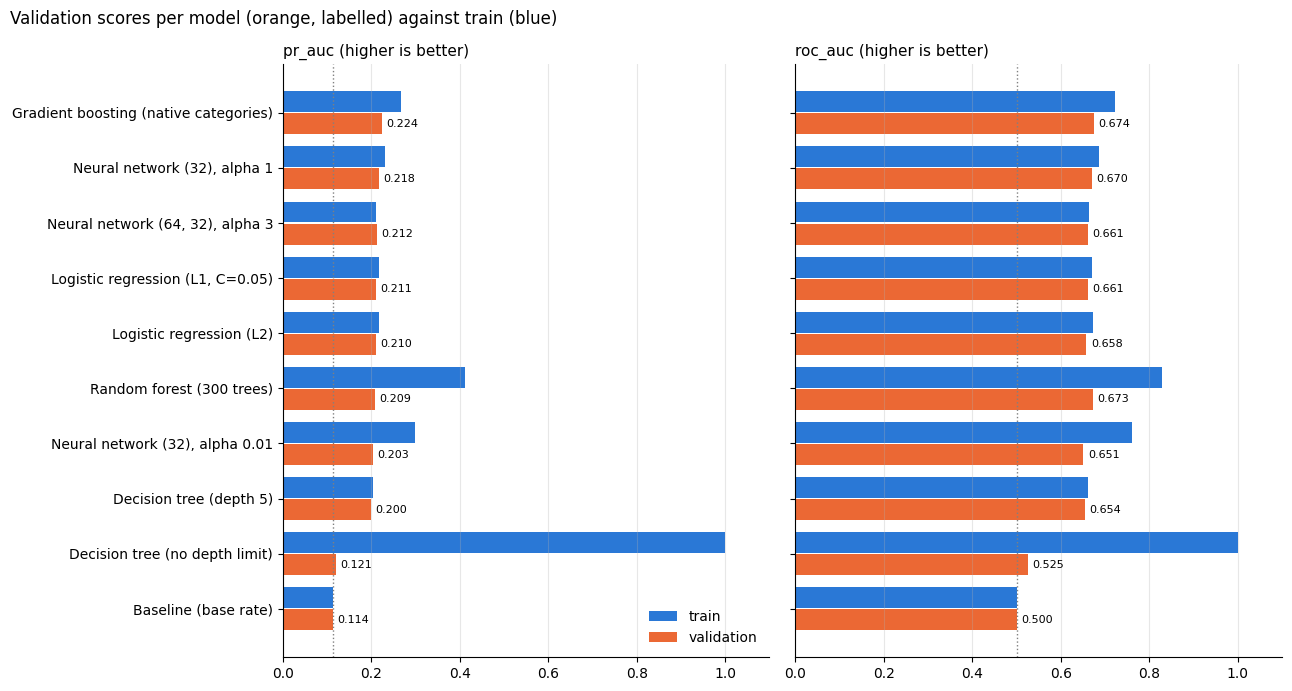

In [33]:
TRAIN_COLOR, VAL_COLOR, TEST_COLOR = "#2a78d6", "#eb6834", "#1baf7a"
order = list(matrix.index)[::-1]  # best on top
positions = np.arange(len(order))

table = show()
on_train = table[table["dataset"] == "train"].set_index("model")
on_val = table[table["dataset"] == "validation"].set_index("model")

fig, axes = plt.subplots(1, 2, figsize=(13, 0.55 * len(order) + 1.5), sharey=True)
for ax, metric in zip(axes, ["pr_auc", "roc_auc"]):
    train_values = on_train.loc[order, metric]
    val_values = on_val.loc[order, metric]
    ax.barh(
        positions + 0.2, train_values, height=0.38, color=TRAIN_COLOR, label="train"
    )
    ax.barh(
        positions - 0.2, val_values, height=0.38, color=VAL_COLOR, label="validation"
    )
    for y_pos, value in zip(positions - 0.2, val_values):
        ax.text(value + 0.01, y_pos, f"{value:.3f}", va="center", fontsize=8)
    ax.set_xlim(0, 1.1)
    ax.set_title(f"{metric} (higher is better)", loc="left", fontsize=11)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
axes[0].axvline(y_train.mean(), color="gray", linestyle=":", linewidth=1)
axes[1].axvline(0.5, color="gray", linestyle=":", linewidth=1)
axes[0].set_yticks(positions, order)
axes[0].legend(loc="lower right", frameon=False)
fig.suptitle(
    "Validation scores per model (orange, labelled) against train (blue)",
    x=0.01,
    ha="left",
    fontsize=12,
)
fig.tight_layout()
plt.show()

**4.14 What the matrix tells me.** (The numbers below are from my run; with
`SEED = 42` they come out the same every time.)

- **This is a hard problem.** Every reasonable model ends up between 0.20 and 0.23
  PR-AUC and between 0.65 and 0.68 ROC-AUC on validation. That is about twice the
  baseline (0.114), so the models do find real signal, but far from a perfect ranking.
  The data has no lab values over time, no social information and no notes, so a
  ceiling around 0.68 ROC-AUC is what I expected for this dataset.
- **Accuracy is useless here.** The baseline has the best accuracy of the table
  (0.886) while catching no readmission at all.
- **Overfitting is visible in the gap column.** The tree with no depth limit is
  perfect on train (1.000) and barely above a coin on validation (0.121). The random
  forest also memorises (0.413 on train against 0.209 on validation), but averaging
  300 trees keeps its validation score at the level of the logistic regression.
- **The penalty fixed the neural network.** With `alpha=0.01` it reached 0.300 on train
  and 0.203 on validation; with `alpha=1` the gap almost disappears (0.232 / 0.218) and
  the validation score is better. The deeper network does not add anything.
- **L1 drops 67 of the 150 features at no cost**: the L1 and L2 logistic regressions
  score the same, so many of the dummies are not needed.
- **Gradient boosting is the best on validation**, by a small margin. Stage 5 checks
  whether that margin is real or luck.

----------------------------------------------------------------------
# STAGE 5. IS THE RANKING STABLE? GROUPED CROSS-VALIDATION
----------------------------------------------------------------------
**5.1** One validation set is one sample of patients: a difference of 0.005 in PR-AUC
between two models could just be luck. So before choosing, I take the 3 best models on
validation and score them with 5-fold cross-validation on train + validation
(the test set stays closed). The baseline and the models I made bad on purpose (the
unlimited tree, the weakly penalised network) are not candidates. I also add the best
logistic regression if it is not already in the top 3: it is the simplest model to
explain, so I want to know how far it really is from the best one.

Two rules against leakage here:

- `GroupKFold` on `patient_nbr`: in each fold, a patient is either in the 4 parts used
  to fit or in the 1 part used to score, never in both.
- **The preprocessing is learned again inside each fold**, on the fitting part only. If
  I reused the preprocessing learned in Stage 3, its statistics would include rows
  that are scored in some folds. That is why I wrote the preprocessing as two
  functions: here I just call `fit_preprocessor` on each fitting part.

This cell takes a minute or two.

In [34]:
on_purpose = set(show().query("note.str.contains('on purpose')")["model"])
candidates = [
    m for m in matrix.index if m != "Baseline (base rate)" and m not in on_purpose
]
shortlist = candidates[:3]
best_logistic = next(m for m in candidates if m.startswith("Logistic"))
if best_logistic not in shortlist:
    shortlist.append(best_logistic)
print("Cross-validated:", shortlist)

folds = GroupKFold(n_splits=5)

cv_rows = []
for name in shortlist:
    kind, build, weighted = recipes[name]
    for fold, (fit_idx, score_idx) in enumerate(
        folds.split(dev, groups=dev[GROUP]), start=1
    ):
        fit_rows, score_rows = dev.iloc[fit_idx], dev.iloc[score_idx]
        prep = fit_preprocessor(fit_rows, kind)  # learned inside the fold
        model = fit_model(
            build, kind, transform(fit_rows, prep), fit_rows[TARGET], weighted
        )
        p = model.predict_proba(transform(score_rows, prep))[:, 1]
        cv_rows.append({"model": name, "fold": fold} | scores(score_rows[TARGET], p))

cv = pd.DataFrame(cv_rows)
cv_summary = cv.groupby("model")[
    ["pr_auc", "roc_auc", "precision_top10", "recall_top10"]
].agg(["mean", "std"])
cv_summary = cv_summary.sort_values(("pr_auc", "mean"), ascending=False)
cv_summary.round(3)

Cross-validated: ['Gradient boosting (native categories)', 'Neural network (32), alpha 1', 'Neural network (64, 32), alpha 3', 'Logistic regression (L1, C=0.05)']


pr_auc        roc_auc        precision_top10        recall_top10       
                                        mean    std    mean    std            mean    std         mean    std
model                                                                                                        
Gradient boosting (native categories)  0.226  0.012   0.675  0.010           0.267  0.018        0.233  0.016
Neural network (32), alpha 1           0.218  0.013   0.669  0.012           0.263  0.016        0.230  0.012
Logistic regression (L1, C=0.05)       0.213  0.013   0.664  0.011           0.257  0.020        0.224  0.017
Neural network (64, 32), alpha 3       0.209  0.015   0.660  0.012           0.246  0.020        0.215  0.016

**5.2 Is the difference real?** The differences between the means (about 0.01) are
about as large as the standard deviations, so at first sight it looks like a tie. But
the standard deviation mostly measures how hard each fold is (some groups of patients
are easier to predict than others), and that affects every model in the same way.
Since all models were scored on the **same** five folds, the fair comparison is fold
by fold: in how many folds does the top model beat each of the others?

In [35]:
by_fold = cv.pivot(index="fold", columns="model", values="pr_auc")
top = cv_summary.index[0]
others = by_fold.drop(columns=top)
paired = pd.DataFrame(
    {
        "folds_won_by_top_model": (others.rsub(by_fold[top], axis=0) > 0).sum(),
        "mean_difference": others.rsub(by_fold[top], axis=0).mean(),
    }
)
print("Top model:", top)
display(by_fold.round(3))
paired.round(3)

Top model: Gradient boosting (native categories)


model,Gradient boosting (native categories),"Logistic regression (L1, C=0.05)","Neural network (32), alpha 1","Neural network (64, 32), alpha 3"
fold,,,,
1,0.220,0.207,0.218,0.206
2,0.217,0.201,0.207,0.196
3,0.216,0.206,0.205,0.195
4,0.235,0.224,0.229,0.222
5,0.243,0.231,0.233,0.228


,folds_won_by_top_model,mean_difference
model,,
"Logistic regression (L1, C=0.05)",5,0.013
"Neural network (32), alpha 1",5,0.008
"Neural network (64, 32), alpha 3",5,0.017


**5.3 The choice.** I take the model with the best **mean** PR-AUC across the 5 folds.
This is the only place where I choose. My rule: if the top model did not beat a
simpler one in at least 4 of the 5 folds, I would call it a tie and prefer the simpler
model (a logistic regression is easier to explain and to audit than boosting or a
network). In my run, gradient boosting beats every other model in all 5 folds, so
its lead is small but consistent, and it is the choice.

In [36]:
best = cv_summary.index[0]
best_kind = recipes[best][0]
print(f"Chosen model : {best}  (preprocessing: {best_kind})")
print(
    f"CV PR-AUC    : {cv_summary.loc[best, ('pr_auc', 'mean')]:.3f}"
    f" ± {cv_summary.loc[best, ('pr_auc', 'std')]:.3f}"
)

Chosen model : Gradient boosting (native categories)  (preprocessing: boosting)
CV PR-AUC    : 0.226 ± 0.012


**5.4 The threshold.** The model gives probabilities; to act, the hospital needs a
rule. With balanced class weights, 0.5 is not "50% risk", so I prefer a **capacity
rule**: follow up the 10% or 20% of patients with the highest risk. I compute, on
validation, the probability that corresponds to each capacity, and what precision and
recall it gives. (I look at this on validation, never on test.)

In [37]:
p_val = fitted[best].predict_proba(X[best_kind]["validation"])[:, 1]
rows = []
for capacity in [0.05, 0.10, 0.20, 0.30]:
    threshold = np.quantile(p_val, 1 - capacity)
    flagged = p_val >= threshold
    rows.append(
        {
            "follow_up_share": capacity,
            "threshold": threshold,
            "precision": metrics.precision_score(y_val, flagged),
            "recall": metrics.recall_score(y_val, flagged),
            "readmissions_caught": int((flagged & (y_val == 1)).sum()),
            "of_total": int(y_val.sum()),
        }
    )
pd.DataFrame(rows).round(3)

,follow_up_share,threshold,precision,recall,readmissions_caught,of_total
0,0.05,0.696,0.313,0.137,309,2252
1,0.10,0.643,0.264,0.231,520,2252
2,0.20,0.577,0.227,0.398,897,2252
3,0.30,0.522,0.196,0.516,1161,2252


How to read it: if the hospital calls the 10% of patients with the highest risk, about
26% of them are really readmitted within 30 days, against 11% if it called patients at
random, so each call is about 2.3 times more useful. But that only catches about a
quarter of all readmissions. Choosing the capacity is a business decision (how many
follow-up calls can the team make?), not a modelling one, so I leave the table here
for that discussion and do not fix a threshold.

----------------------------------------------------------------------
# STAGE 6. THE TEST SET, ONCE
----------------------------------------------------------------------
**6.1** I save the matrix to `reports/experiments-readmission.csv`. This file is my
experiment log: if I change a model later, I restart the kernel, run everything again,
and the log shows the new results next to the date.

In [38]:
(PROJECT / "reports").mkdir(exist_ok=True)
LOG = PROJECT / "reports" / "experiments-readmission.csv"
show().to_csv(LOG, index=False)
print("Saved", LOG.relative_to(PROJECT), "with", len(results), "rows")

Saved reports/experiments-readmission.csv with 20 rows


**6.2** Now, and only now, I open the test set. The winner was chosen in step 5.3 and
I do not choose again here.

Before scoring it, I refit the winner on **train + validation**: the choice is already
made, so the validation rows can now be used to learn, and 80% of the patients give a
better model than 60%. To keep the rule of Stage 3, the preprocessing is also learned
again, on train + validation only, and then applied to the test rows. The test set is
never used to learn anything.

In [39]:
kind, build, weighted = recipes[best]
final_prep = fit_preprocessor(dev, kind)
X_dev, X_test = transform(dev, final_prep), transform(test, final_prep)
final_model = fit_model(build, kind, X_dev, dev[TARGET], weighted)

p_test = final_model.predict_proba(X_test)[:, 1]
results.append(
    {"date": today, "model": best, "preprocessing": kind, "dataset": "test"}
    | scores(y_test, p_test)
    | {"note": "refit on train+validation, test opened once"}
)
show().to_csv(LOG, index=False)
show().query("model == @best")

,date,model,preprocessing,dataset,pr_auc,roc_auc,precision_top10,recall_top10,accuracy,balanced_accuracy,precision,recall,f1,log_loss,brier,note
12,2026-10-14,Gradient boosting (native categories),boosting,train,0.268,0.723,0.311,0.272,0.672,0.659,0.204,0.641,0.309,0.618,0.214,
13,2026-10-14,Gradient boosting (native categories),boosting,validation,0.224,0.674,0.264,0.231,0.660,0.621,0.183,0.570,0.277,0.625,0.217,
20,2026-10-14,Gradient boosting (native categories),boosting,test,0.232,0.676,0.279,0.249,0.656,0.630,0.182,0.595,0.279,0.630,0.219,"refit on train+validation, test opened once"


If the test scores are close to the cross-validation scores of step 5.1, the model
generalises to patients it has never seen, and the grouped split did its job. If they
were much lower, something leaked during development; if they were much higher, it
would most likely be luck in the test sample.

In my run: PR-AUC 0.226 ± 0.012 in cross-validation and 0.232 on test, ROC-AUC 0.675
and 0.676. The test score is within the range of the folds, so there is no sign of
leakage, and the model behaves on new patients as it did during development.

**6.3 ROC and precision-recall curves of the winner.** The ROC curve shows the share of
readmissions caught against the share of non-readmitted patients flagged by mistake,
at every threshold (the dotted diagonal is a coin). The precision-recall curve shows,
for each share of readmissions caught, what share of the flagged patients are really
readmitted (the dotted line is the positive rate, again a coin). Train and validation
come from the model fitted in Stage 4; test from the refitted final model.

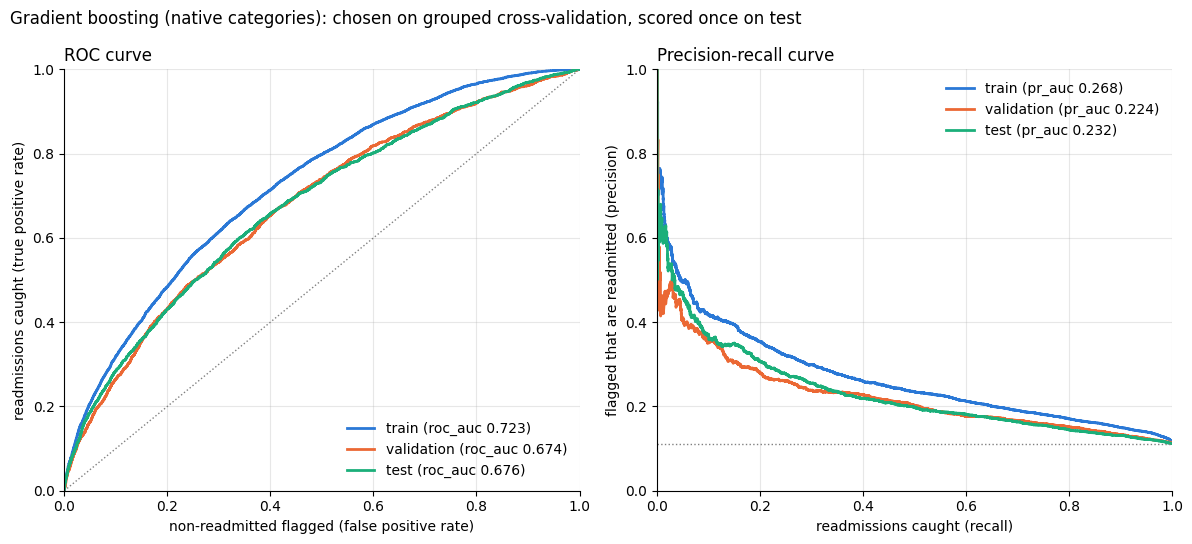

In [40]:
curves = [
    (
        "train",
        Y["train"],
        fitted[best].predict_proba(X[best_kind]["train"])[:, 1],
        TRAIN_COLOR,
    ),
    ("validation", Y["validation"], p_val, VAL_COLOR),
    ("test", y_test, p_test, TEST_COLOR),
]
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5.5))
for dataset, y, p, color in curves:
    fpr, tpr, _ = metrics.roc_curve(y, p)
    ax_roc.plot(
        fpr,
        tpr,
        color=color,
        linewidth=2,
        label=f"{dataset} (roc_auc {metrics.roc_auc_score(y, p):.3f})",
    )
    precision, recall, _ = metrics.precision_recall_curve(y, p)
    ax_pr.plot(
        recall,
        precision,
        color=color,
        linewidth=2,
        label=f"{dataset} (pr_auc {metrics.average_precision_score(y, p):.3f})",
    )
ax_roc.plot([0, 1], [0, 1], color="gray", linestyle=":", linewidth=1)
ax_pr.axhline(y_test.mean(), color="gray", linestyle=":", linewidth=1)
ax_roc.set(
    xlabel="non-readmitted flagged (false positive rate)",
    ylabel="readmissions caught (true positive rate)",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax_pr.set(
    xlabel="readmissions caught (recall)",
    ylabel="flagged that are readmitted (precision)",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax_roc.set_title("ROC curve", loc="left")
ax_pr.set_title("Precision-recall curve", loc="left")
for ax in (ax_roc, ax_pr):
    ax.legend(loc="lower right" if ax is ax_roc else "upper right", frameon=False)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.grid(alpha=0.3)
fig.suptitle(
    f"{best}: chosen on grouped cross-validation, scored once on test",
    x=0.01,
    ha="left",
    fontsize=12,
)
fig.tight_layout()
plt.show()

----------------------------------------------------------------------
# SUMMARY
----------------------------------------------------------------------
What I did to avoid leakage, in one list:

1. **Only row-by-row rules before the split** (`clean`): removing death/hospice,
   the target, the diagnosis groups, the medication counts. Nothing there is computed
   from other rows.
2. **Split by patient** (`GroupShuffleSplit` on `patient_nbr`), checked with `assert`:
   no patient is in two sets.
3. **Preprocessing learned on training only** (`fit_preprocessor`) and applied unchanged
   to the other sets (`transform`): the frequent levels of each category, the means and
   standard deviations used to scale. Even the choice of not using `log1p` and clipping
   was made on validation, not on test.
4. **No random internal splits** inside the models: early stopping is off in gradient
   boosting and in the neural networks, because it would split by row and mix patients.
5. **Cross-validation grouped by patient**, with the preprocessing learned again inside
   each fold.
6. **One choice, on validation / cross-validation only**, and the test set opened once,
   after the choice, with the preprocessing learned on train + validation.

How the notebook follows the project brief
(`docs/EDSB_2026_Project_Diabetes_Hospital_Readmission_V2.pdf`):

| Brief | Where |
|---|---|
| Score the risk **at discharge** of a `<30` readmission and use it to prioritise follow-up | Target in `clean` (step 1.6); features all known at discharge; capacity table in step 5.4 |
| Decode the IDs with the lookup table before interpreting or filtering them | Steps 1.2 and 1.3: decoded table, death/hospice codes found in the lookup |
| `?` is missing; `None` in the lab tests means "not measured" | `load_raw()`; `None` kept as a level |
| `weight`: do not cast the bands to numbers | Dropped (96.9% missing) |
| `age`: bands are intervals, not exact ages | `age_band_order` keeps only the order; the literal band is kept as reference |
| `gender`: keep the 3 `Unknown/Invalid` as unknown, do not infer | Level kept as is, not merged (step 3.1) |
| `race`: preserve the source spelling | Values unchanged; missing -> `Unknown`; the rare bucket is `Rare`, not `Other` |
| `payer_code`: keep the codes, do not invent expansions | Codes used as they are |
| `diag_*`: preserve the raw string before grouping; Strack et al. groups | New `*_group` columns, raw strings kept as reference (step 1.5) |
| `patient_nbr` repeats across encounters | Every split grouped on `patient_nbr` |

Two limits the brief asks me to keep in mind when presenting the results:

- The model estimates an **observed** readmission outcome. It says who is likely to
  come back, not that extra follow-up would prevent it: that is a causal question this
  data cannot answer.
- A `NO` or `>30` label does not prove the patient was not readmitted elsewhere: the
  labels only cover the source records.

What I would try next: tuning the winner's hyperparameters with the same grouped
cross-validation; calibrating its probabilities (so that they are real risks, useful
for the doctor); looking at which features drive the predictions (permutation
importance); and checking the scores by `race` and `age` for the fairness audit of
Phase 5 (not by the 3 `Unknown/Invalid` gender encounters, too few to report on, as
the brief warns).